ERA5 DATASET
<xarray.Dataset> Size: 34MB
Dimensions:     (valid_time: 427, latitude: 141, longitude: 141)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 3kB 1991-01-01 ... 2026-07-01
  * latitude    (latitude) float64 1kB 20.0 19.75 19.5 ... -14.5 -14.75 -15.0
  * longitude   (longitude) float64 1kB 20.0 20.25 20.5 ... 54.5 54.75 55.0
    expver      (valid_time) <U4 7kB ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 34MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-08-16T12:10 GRIB to CDM+CF via cfgrib-0.9.1...

Variable:
<xarray.DataArray 't2m' (valid_time: 427, latitude: 141, longitude: 141)> Size: 34MB
[8489187 values with dtype=float32]
Coordinates:
 

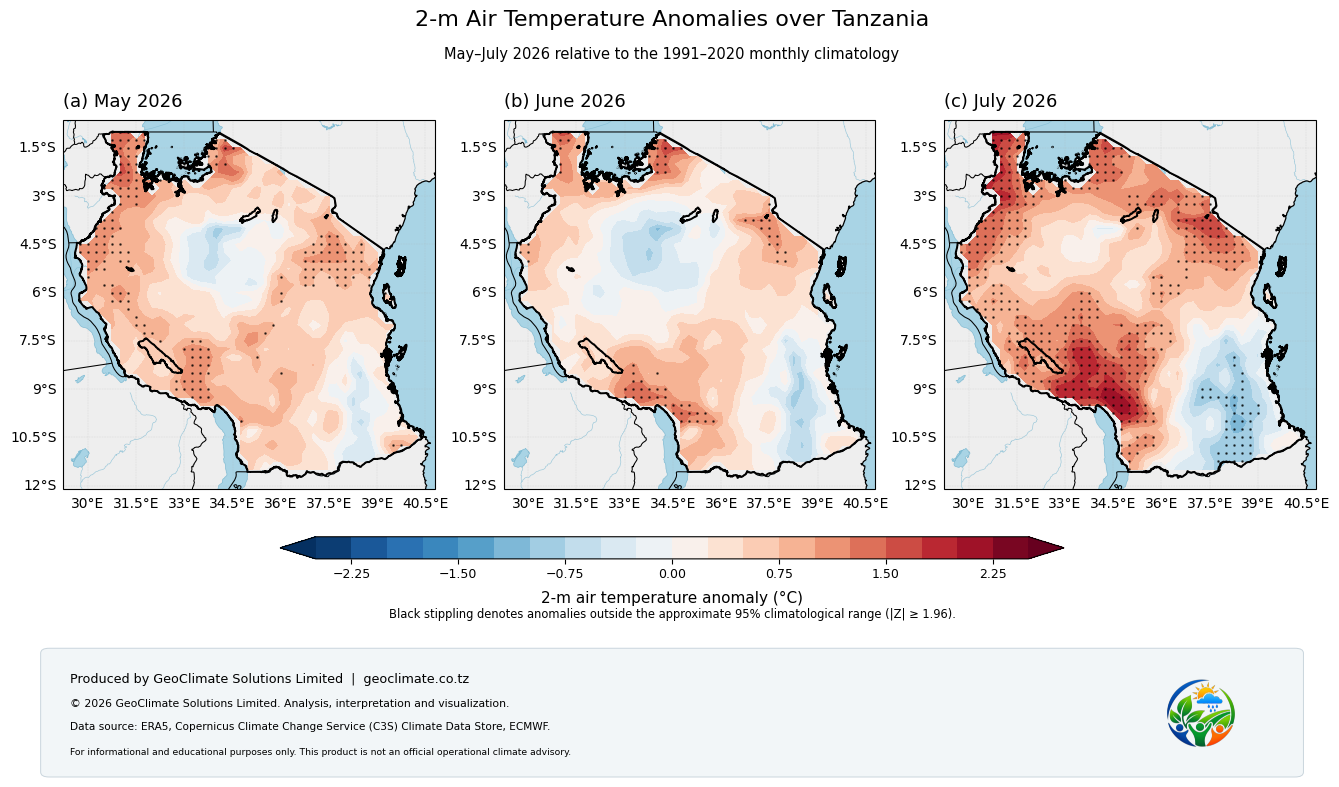


Static figure saved as:
D:\JJA_analysis\outputs\Tanzania_T2M_Anomaly_MJJ_2026_GeoClimate.png

COMPLETED

Static figure saved as:
D:\JJA_analysis\outputs\Tanzania_T2M_Anomaly_MJJ_2026_GeoClimate.png


In [4]:
# ============================================================
# TANZANIA 2-M AIR TEMPERATURE ANOMALY
# May, June and July 2026
# Relative to 1991–2020 monthly climatology
#
# ERA5 monthly t2m + TZwards.shp + Cartopy
#
# Black stippling:
# |Z| >= 1.96 relative to 1991–2020 monthly distribution
#
# Produced by GeoClimate Solutions Limited
# geoclimate.co.tz
#
# Output:
#   1. Static PNG with May, June and July panels
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
from pathlib import Path as FilePath

import xarray as xr
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import geopandas as gpd

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.path import Path
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import FancyBboxPatch


# ============================================================
# 2. SETTINGS
# ============================================================

# All input files are expected inside this folder.
PROJECT_DIR = FilePath(r"D:\JJA_analysis")

# Input files
ERA5_FILE = PROJECT_DIR / "era5_monthly_t2m_1991_2026.nc"
SHAPEFILE = PROJECT_DIR / "TZwards.shp"
LOGO_FILE = PROJECT_DIR / "logo.png"  # Optional; script continues if missing

# Save generated figures/videos in this folder.
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STATIC_OUTPUT = OUTPUT_DIR / "Tanzania_T2M_Anomaly_MJJ_2026_GeoClimate.png"

VAR = "t2m"

# Fail early with a useful message if an input path is incorrect.
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(f"Project folder was not found: {PROJECT_DIR}")
if not ERA5_FILE.is_file():
    available_nc = sorted(p.name for p in PROJECT_DIR.glob("*.nc"))
    raise FileNotFoundError(
        f"ERA5 NetCDF file was not found: {ERA5_FILE}\n"
        f"NetCDF files found in {PROJECT_DIR}: {available_nc}\n"
        "Update ERA5_FILE to the exact filename shown above."
    )
if not SHAPEFILE.is_file():
    available_shp = sorted(p.name for p in PROJECT_DIR.glob("*.shp"))
    raise FileNotFoundError(
        f"Ward shapefile was not found: {SHAPEFILE}\n"
        f"Shapefiles found in {PROJECT_DIR}: {available_shp}\n"
        "Update SHAPEFILE to the exact .shp filename. Keep its .dbf, .shx and .prj sidecar files together."
    )


# ------------------------------------------------------------
# CLIMATOLOGICAL BASELINE
# ------------------------------------------------------------

BASE_START = "1991-01-01"
BASE_END   = "2020-12-31"


# ------------------------------------------------------------
# TARGET PERIOD
# ------------------------------------------------------------

TARGET_YEAR = 2026

MONTHS = [5, 6, 7]

MONTH_NAMES = {
    5: "May",
    6: "June",
    7: "July"
}


# ------------------------------------------------------------
# OUTPUT FILES
# ------------------------------------------------------------

# Output paths are defined above in OUTPUT_DIR.


# ------------------------------------------------------------
# APPROXIMATE 95% CLIMATOLOGICAL THRESHOLD
# ------------------------------------------------------------

Z_THRESHOLD = 1.96


# ------------------------------------------------------------
# MAP PADDING AROUND TANZANIA
# ------------------------------------------------------------

PAD = 0.35


# ============================================================
# 3. OPEN ERA5 DATA
# ============================================================

ds = xr.open_dataset(
    str(ERA5_FILE)
)


print("========================================")
print("ERA5 DATASET")
print("========================================")

print(ds)


t2m = ds[VAR]


print("\nVariable:")
print(t2m)


print("\nOriginal units:")
print(
    t2m.attrs.get(
        "units",
        "Not specified"
    )
)


# ============================================================
# 4. IDENTIFY TIME COORDINATE
# ============================================================

if "valid_time" in t2m.dims:

    TIME = "valid_time"

elif "time" in t2m.dims:

    TIME = "time"

else:

    raise ValueError(
        "Could not identify valid_time or time."
    )


print("\nTime coordinate:")
print(TIME)


print("\nFirst timestamp:")
print(
    t2m[TIME].values[0]
)


print("\nLast timestamp:")
print(
    t2m[TIME].values[-1]
)


# ============================================================
# 5. HANDLE EXPVER IF PRESENT
# ============================================================

if "expver" in t2m.dims:

    print(
        "\nexpver dimension detected."
    )

    t2m = t2m.max(
        dim="expver",
        skipna=True
    )


# ============================================================
# 6. CONVERT KELVIN TO CELSIUS
# ============================================================

units = str(
    t2m.attrs.get(
        "units",
        ""
    )
).lower()


if (
    units == "k"
    or "kelvin" in units
):

    print(
        "\nConverting Kelvin to Celsius..."
    )

    t2m = (
        t2m
        -
        273.15
    )


t2m.attrs["units"] = "°C"


# ============================================================
# 7. READ TANZANIA WARDS SHAPEFILE
# ============================================================

wards = gpd.read_file(
    str(SHAPEFILE)
)


if wards.crs is None:

    raise ValueError(
        "TZwards.shp has no CRS information."
    )


wards = wards.to_crs(
    epsg=4326
)


# ============================================================
# 8. CREATE TANZANIA NATIONAL BOUNDARY
# ============================================================

tanzania = wards.dissolve()


# ------------------------------------------------------------
# REPAIR POSSIBLE GEOMETRY ISSUES
# ------------------------------------------------------------

tanzania["geometry"] = (
    tanzania.geometry.buffer(0)
)


# ============================================================
# 9. TANZANIA EXTENT
# ============================================================

minx, miny, maxx, maxy = (
    tanzania.total_bounds
)


LON_MIN = minx - PAD
LON_MAX = maxx + PAD

LAT_MIN = miny - PAD
LAT_MAX = maxy + PAD


print("\n========================================")
print("TANZANIA MAP EXTENT")
print("========================================")

print(
    "Longitude:",
    LON_MIN,
    "to",
    LON_MAX
)

print(
    "Latitude:",
    LAT_MIN,
    "to",
    LAT_MAX
)


# ============================================================
# 10. SUBSET ERA5 TO TANZANIA
# ============================================================

lat_values = (
    t2m.latitude.values
)


if (
    lat_values[0]
    >
    lat_values[-1]
):

    # ERA5 usually stores latitude north -> south

    t2m_tz = t2m.sel(

        longitude=slice(
            LON_MIN,
            LON_MAX
        ),

        latitude=slice(
            LAT_MAX,
            LAT_MIN
        )
    )

else:

    t2m_tz = t2m.sel(

        longitude=slice(
            LON_MIN,
            LON_MAX
        ),

        latitude=slice(
            LAT_MIN,
            LAT_MAX
        )
    )


print("\nTanzania subset:")
print(
    t2m_tz.sizes
)


# ============================================================
# 11. SELECT 1991–2020 BASELINE
# ============================================================

baseline = t2m_tz.sel({

    TIME:
        slice(
            BASE_START,
            BASE_END
        )

})


# ============================================================
# 12. MONTHLY CLIMATOLOGICAL MEAN
# ============================================================

clim_mean = (

    baseline

    .groupby(
        f"{TIME}.month"
    )

    .mean(
        TIME,
        skipna=True
    )
)


# ============================================================
# 13. MONTHLY CLIMATOLOGICAL STANDARD DEVIATION
# ============================================================

clim_std = (

    baseline

    .groupby(
        f"{TIME}.month"
    )

    .std(
        TIME,
        skipna=True,
        ddof=1
    )
)


# ============================================================
# 14. CALCULATE 2026 ANOMALIES AND Z-SCORES
# ============================================================

anomalies = {}

z_scores = {}

significant = {}


for month in MONTHS:


    # --------------------------------------------------------
    # SELECT TARGET MONTH
    # --------------------------------------------------------

    target = t2m_tz.where(

        (
            t2m_tz[TIME].dt.year
            ==
            TARGET_YEAR
        )

        &

        (
            t2m_tz[TIME].dt.month
            ==
            month
        ),

        drop=True
    )


    # Monthly file should have one record/month.
    # Mean keeps the code robust.

    target_month = target.mean(
        TIME,
        skipna=True
    )


    # --------------------------------------------------------
    # TEMPERATURE ANOMALY
    # --------------------------------------------------------

    anomaly = (

        target_month

        -

        clim_mean.sel(
            month=month
        )
    )


    # --------------------------------------------------------
    # STANDARD DEVIATION FOR SAME CALENDAR MONTH
    # --------------------------------------------------------

    std_month = clim_std.sel(
        month=month
    )


    # --------------------------------------------------------
    # STANDARDIZED ANOMALY / Z-SCORE
    # --------------------------------------------------------

    z = (
        anomaly
        /
        std_month
    )


    # --------------------------------------------------------
    # APPROXIMATE 95% CLIMATOLOGICAL RANGE
    # --------------------------------------------------------

    sig = (
        np.abs(z)
        >=
        Z_THRESHOLD
    )


    # --------------------------------------------------------
    # REMOVE SCALAR MONTH COORDINATE
    # --------------------------------------------------------

    anomaly = anomaly.drop_vars(
        "month",
        errors="ignore"
    )

    z = z.drop_vars(
        "month",
        errors="ignore"
    )

    sig = sig.drop_vars(
        "month",
        errors="ignore"
    )


    anomalies[month] = anomaly

    z_scores[month] = z

    significant[month] = sig


# ============================================================
# 15. PREPARE TANZANIA MASK
# ============================================================

lon = (
    t2m_tz.longitude.values
)

lat = (
    t2m_tz.latitude.values
)


lon2d, lat2d = np.meshgrid(
    lon,
    lat
)


points = np.column_stack(
    [
        lon2d.ravel(),
        lat2d.ravel()
    ]
)


# ============================================================
# 16. CONVERT TANZANIA GEOMETRY TO MATPLOTLIB PATHS
# ============================================================

geom = (
    tanzania.geometry.iloc[0]
)


def geometry_to_paths(geometry):

    paths = []


    if geometry.geom_type == "Polygon":

        polygons = [
            geometry
        ]


    elif geometry.geom_type == "MultiPolygon":

        polygons = list(
            geometry.geoms
        )


    else:

        raise ValueError(
            f"Unsupported geometry type: "
            f"{geometry.geom_type}"
        )


    for polygon in polygons:

        coordinates = np.asarray(
            polygon.exterior.coords
        )

        paths.append(
            Path(
                coordinates
            )
        )


    return paths


tz_paths = geometry_to_paths(
    geom
)


# ============================================================
# 17. CREATE TANZANIA GRID MASK
# ============================================================

inside = np.zeros(
    len(points),
    dtype=bool
)


for path in tz_paths:

    inside |= (
        path.contains_points(
            points
        )
    )


inside = inside.reshape(
    lon2d.shape
)


tz_mask = xr.DataArray(

    inside,

    coords={

        "latitude":
            t2m_tz.latitude,

        "longitude":
            t2m_tz.longitude
    },

    dims=[
        "latitude",
        "longitude"
    ]
)


# ============================================================
# 18. APPLY TANZANIA MASK
# ============================================================

for month in MONTHS:

    anomalies[month] = (
        anomalies[month]
        .where(tz_mask)
    )

    z_scores[month] = (
        z_scores[month]
        .where(tz_mask)
    )

    significant[month] = (
        significant[month]
        .where(tz_mask)
    )


# ============================================================
# 19. PRINT BASIC STATISTICS
# ============================================================

print("\n========================================")
print("TANZANIA TEMPERATURE ANOMALIES")
print("========================================")


for month in MONTHS:

    field = anomalies[month]


    print(
        f"\n{MONTH_NAMES[month]} "
        f"{TARGET_YEAR}"
    )


    print(
        "Minimum:",
        round(
            float(
                field.min(
                    skipna=True
                )
            ),
            2
        ),
        "°C"
    )


    print(
        "Maximum:",
        round(
            float(
                field.max(
                    skipna=True
                )
            ),
            2
        ),
        "°C"
    )


    print(
        "Spatial mean:",
        round(
            float(
                field.mean(
                    skipna=True
                )
            ),
            2
        ),
        "°C"
    )


# ============================================================
# 20. COMMON COLOUR SCALE
# ============================================================

vmax = max(

    float(
        np.abs(
            anomalies[month]
        ).max(
            skipna=True
        )
    )

    for month in MONTHS
)


# ------------------------------------------------------------
# ROUND UPWARD TO NEAREST 0.5°C
# ------------------------------------------------------------

vmax = (
    np.ceil(
        vmax / 0.5
    )
    *
    0.5
)


# Ensure minimum useful range

vmax = max(
    vmax,
    1.0
)


VMIN = -vmax

VMAX = vmax


CONTOUR_INTERVAL = 0.25


levels = np.arange(

    VMIN,

    VMAX
    +
    CONTOUR_INTERVAL,

    CONTOUR_INTERVAL
)


print(
    "\nCommon colour scale:",
    VMIN,
    "to",
    VMAX,
    "°C"
)


# ============================================================
# 21. CARTOPY BACKGROUND FUNCTION
# ============================================================

def add_cartopy_background(ax):


    # --------------------------------------------------------
    # LAND
    # --------------------------------------------------------

    ax.add_feature(

        cfeature.LAND,

        facecolor="#eeeeee",

        edgecolor="none",

        zorder=0
    )


    # --------------------------------------------------------
    # OCEAN
    # --------------------------------------------------------

    ax.add_feature(

        cfeature.OCEAN,

        facecolor="#a9d4e5",

        zorder=0
    )


    # --------------------------------------------------------
    # LAKES
    # --------------------------------------------------------

    ax.add_feature(

        cfeature.LAKES,

        facecolor="#a9d4e5",

        edgecolor="#83bdd4",

        linewidth=0.5,

        zorder=1
    )


    # --------------------------------------------------------
    # RIVERS
    # --------------------------------------------------------

    ax.add_feature(

        cfeature.RIVERS,

        edgecolor="#83bdd4",

        linewidth=0.45,

        alpha=0.8,

        zorder=2
    )


    # --------------------------------------------------------
    # COUNTRY BORDERS
    # --------------------------------------------------------

    ax.add_feature(

        cfeature.BORDERS,

        edgecolor="black",

        linewidth=0.75,

        zorder=6
    )


    # --------------------------------------------------------
    # COASTLINE
    # --------------------------------------------------------

    ax.add_feature(

        cfeature.COASTLINE,

        edgecolor="black",

        linewidth=0.9,

        zorder=6
    )


# ============================================================
# 22. SIGNIFICANCE STIPPLING FUNCTION
# ============================================================

def add_significance(ax, sig):


    sig_array = (
        sig.values
    )


    iy, ix = np.where(
        sig_array == True
    )


    if len(ix) == 0:

        return


    sig_lon = (
        sig.longitude.values[ix]
    )


    sig_lat = (
        sig.latitude.values[iy]
    )


    ax.scatter(

        sig_lon,

        sig_lat,

        s=3,

        c="black",

        marker=".",

        alpha=0.65,

        transform=
            ccrs.PlateCarree(),

        zorder=8
    )


# ============================================================
# 23. STATIC FIGURE
# ============================================================

fig, axes = plt.subplots(

    nrows=1,

    ncols=3,

    figsize=(14, 8.2),

    subplot_kw={
        "projection":
            ccrs.PlateCarree()
    }
)


panel_labels = {

    5: "(a)",

    6: "(b)",

    7: "(c)"
}


# ============================================================
# 24. DRAW STATIC PANELS
# ============================================================

for ax, month in zip(
    axes,
    MONTHS
):


    field = anomalies[month]

    sig = significant[month]


    # --------------------------------------------------------
    # MAP EXTENT
    # --------------------------------------------------------

    ax.set_extent(

        [
            LON_MIN,
            LON_MAX,
            LAT_MIN,
            LAT_MAX
        ],

        crs=
            ccrs.PlateCarree()
    )


    # --------------------------------------------------------
    # BACKGROUND
    # --------------------------------------------------------

    add_cartopy_background(
        ax
    )


    # --------------------------------------------------------
    # TEMPERATURE ANOMALY
    # --------------------------------------------------------

    cf = ax.contourf(

        field.longitude,

        field.latitude,

        field.values,

        levels=levels,

        cmap="RdBu_r",

        extend="both",

        transform=
            ccrs.PlateCarree(),

        zorder=3
    )


    # --------------------------------------------------------
    # SIGNIFICANCE
    # --------------------------------------------------------

    add_significance(
        ax,
        sig
    )


    # --------------------------------------------------------
    # TANZANIA NATIONAL BOUNDARY
    # --------------------------------------------------------

    ax.add_geometries(

        tanzania.geometry,

        crs=
            ccrs.PlateCarree(),

        facecolor="none",

        edgecolor="black",

        linewidth=1.4,

        zorder=9
    )


    # --------------------------------------------------------
    # GRIDLINES
    # --------------------------------------------------------

    gl = ax.gridlines(

        crs=
            ccrs.PlateCarree(),

        draw_labels=True,

        linewidth=0.35,

        linestyle="--",

        alpha=0.35,

        zorder=10
    )


    gl.top_labels = False

    gl.right_labels = False


    # --------------------------------------------------------
    # PANEL TITLE
    # LEFT-ALIGNED / NON-BOLD
    # --------------------------------------------------------

    ax.set_title(

        f"{panel_labels[month]} "
        f"{MONTH_NAMES[month]} {TARGET_YEAR}",

        loc="left",

        fontsize=13,

        fontweight="normal",

        pad=10
    )


# ============================================================
# 25. STATIC FIGURE LAYOUT
# ============================================================

fig.subplots_adjust(

    left=0.055,

    right=0.97,

    bottom=0.37,

    top=0.82,

    wspace=0.10
)


# ============================================================
# 26. STATIC COLORBAR
# ============================================================

cbar_ax = fig.add_axes(

    [
        0.22,
        0.285,
        0.56,
        0.027
    ]
)


cbar = fig.colorbar(

    cf,

    cax=cbar_ax,

    orientation="horizontal"
)


cbar.set_label(

    "2-m air temperature anomaly (°C)",

    fontsize=11,

    labelpad=7
)


cbar.ax.tick_params(

    labelsize=9,

    pad=3
)


# ============================================================
# 27. MAIN TITLE
# ============================================================

fig.suptitle(

    "2-m Air Temperature Anomalies over Tanzania",

    fontsize=16,

    fontweight="normal",

    y=0.955
)


# ============================================================
# 28. SUBTITLE
# ============================================================

fig.text(

    0.5,

    0.895,

    "May–July 2026 relative to the "
    "1991–2020 monthly climatology",

    ha="center",

    fontsize=10.5
)


# ============================================================
# 29. SIGNIFICANCE NOTE
# ============================================================

fig.text(

    0.5,

    0.218,

    "Black stippling denotes anomalies outside the "
    "approximate 95% climatological range (|Z| ≥ 1.96).",

    ha="center",

    va="center",

    fontsize=8.3
)


# ============================================================
# 30. STATIC GEOCLIMATE INFORMATION BOX
# ============================================================

INFO_LEFT = 0.055

INFO_BOTTOM = 0.025

INFO_WIDTH = 0.89

INFO_HEIGHT = 0.145


info_box = FancyBboxPatch(

    (
        INFO_LEFT,
        INFO_BOTTOM
    ),

    INFO_WIDTH,
    INFO_HEIGHT,

    transform=
        fig.transFigure,

    boxstyle=
        "round,pad=0.006",

    linewidth=0.7,

    edgecolor=
        "#c8d4dc",

    facecolor=
        "#f2f6f8",

    alpha=0.97,

    zorder=20
)


fig.patches.append(
    info_box
)


# ============================================================
# 31. PRODUCER + WEBSITE
# ============================================================

fig.text(

    INFO_LEFT + 0.015,

    INFO_BOTTOM + 0.113,

    "Produced by GeoClimate Solutions Limited"
    "  |  geoclimate.co.tz",

    ha="left",

    va="center",

    fontsize=9.2,

    fontweight="normal",

    zorder=22
)


# ============================================================
# 32. OWNERSHIP
# ============================================================

fig.text(

    INFO_LEFT + 0.015,

    INFO_BOTTOM + 0.084,

    "© 2026 GeoClimate Solutions Limited. "
    "Analysis, interpretation and visualization.",

    ha="left",

    va="center",

    fontsize=7.8,

    zorder=22
)


# ============================================================
# 33. DATA SOURCE
# ============================================================

fig.text(

    INFO_LEFT + 0.015,

    INFO_BOTTOM + 0.055,

    "Data source: ERA5, Copernicus Climate Change Service "
    "(C3S) Climate Data Store, ECMWF.",

    ha="left",

    va="center",

    fontsize=7.6,

    zorder=22
)


# ============================================================
# 34. INFORMATION / EDUCATION DISCLAIMER
# ============================================================

fig.text(

    INFO_LEFT + 0.015,

    INFO_BOTTOM + 0.024,

    "For informational and educational purposes only. "
    "This product is not an official operational climate advisory.",

    ha="left",

    va="center",

    fontsize=6.7,

    zorder=22
)


# ============================================================
# 35. ADD GEOCLIMATE LOGO
# ============================================================

if LOGO_FILE.is_file():

    logo = mpimg.imread(
        LOGO_FILE
    )


    logo_ax = fig.add_axes(

        [
            INFO_LEFT + INFO_WIDTH - 0.115,
            INFO_BOTTOM + 0.023,
            0.095,
            0.095
        ],

        zorder=25
    )


    logo_ax.imshow(
        logo
    )


    logo_ax.axis(
        "off"
    )


else:

    print(
        "\nWARNING: logo.png was not found."
    )


# ============================================================
# 36. SAVE STATIC FIGURE
# ============================================================

plt.savefig(

    str(STATIC_OUTPUT),

    dpi=400,

    bbox_inches="tight",

    facecolor="white"
)


plt.show()


print(
    "\nStatic figure saved as:"
)

print(
    str(STATIC_OUTPUT)
)


# ============================================================
# 37. COMPLETION MESSAGE
# ============================================================

print("\n========================================")
print("COMPLETED")
print("========================================")
print("\nStatic figure saved as:")
print(STATIC_OUTPUT)

